In [1]:

import numpy as np
import matplotlib.pyplot as plt
import time

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

np.random.seed(42)

X = np.random.rand(200, 1) * 100
y = 2 * X[:, 0] + 10 + np.random.randn(200) * 5

X[0] = 500
X[1] = 600

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 160
Testing samples: 40


In [2]:

class CustomTransformer(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        self.lower_ = np.percentile(X, 5, axis=0)
        self.upper_ = np.percentile(X, 95, axis=0)
        return self

    def transform(self, X):
        return np.clip(X, self.lower_, self.upper_)


transformer = CustomTransformer()
transformer.fit(X_train)

X_transformed = transformer.transform(X_train)

print("Before:", X_train[:5].flatten())
print("After:", X_transformed[:5].flatten())


Before: [11.58690595 89.711026   68.42330265 45.60699842 31.8003475 ]
After: [11.58690595 89.711026   68.42330265 45.60699842 31.8003475 ]


In [3]:

pipeline = Pipeline([
    ("custom", CustomTransformer()),
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

pipeline.fit(X_train, y_train)

predictions = pipeline.predict(X_test)

print("Pipeline trained successfully!")
print("MSE:", mean_squared_error(y_test, predictions))


Pipeline trained successfully!
MSE: 26.191323739418703


In [4]:

transformer = pipeline.named_steps["custom"]

lower_before = transformer.lower_.copy()
upper_before = transformer.upper_.copy()

new_data = np.array([[20], [500], [1000]])

result = transformer.transform(new_data)

assert np.array_equal(lower_before, transformer.lower_)
assert np.array_equal(upper_before, transformer.upper_)

print("Test 1 passed!")

expected = np.clip(new_data, lower_before, upper_before)

assert np.array_equal(result, expected)
assert np.array_equal(result, transformer.transform(new_data))

print("Test 2 passed!")


Test 1 passed!
Test 2 passed!


Dataset size: 1000
Time: 0.0052 seconds
Dataset size: 10000
Time: 0.0078 seconds
Dataset size: 100000
Time: 0.0189 seconds


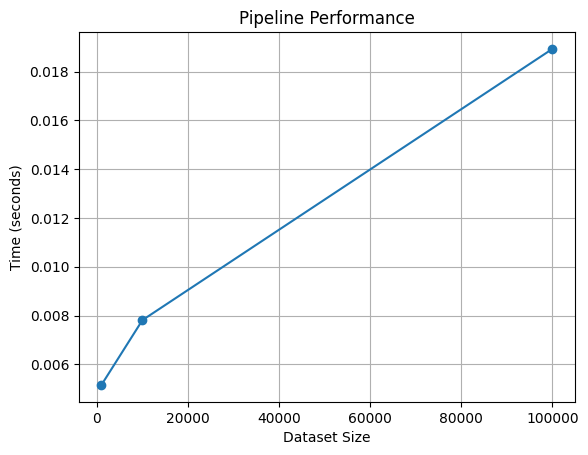

In [5]:

sizes = [1000, 10000, 100000]
times = []

for size in sizes:
    X_large = np.random.rand(size, 1) * 100
    y_large = 2 * X_large[:, 0] + 10

    start = time.perf_counter()

    pipeline.fit(X_large, y_large)
    pipeline.predict(X_large)

    elapsed = time.perf_counter() - start

    times.append(elapsed)

    print("Dataset size:", size)
    print("Time:", round(elapsed, 4), "seconds")

plt.plot(sizes, times, marker="o")
plt.xlabel("Dataset Size")
plt.ylabel("Time (seconds)")
plt.title("Pipeline Performance")
plt.grid(True)
plt.show()


In [6]:

X_large = np.random.rand(100000, 1) * 100
y_large = 2 * X_large[:, 0] + 10

transformer = CustomTransformer()
scaler = StandardScaler()
model = LinearRegression()

start = time.perf_counter()
X_custom = transformer.fit_transform(X_large)
custom_time = time.perf_counter() - start

start = time.perf_counter()
X_scaled = scaler.fit_transform(X_custom)
scaler_time = time.perf_counter() - start

start = time.perf_counter()
model.fit(X_scaled, y_large)
model_time = time.perf_counter() - start

print("Custom transformer:", round(custom_time, 5), "seconds")
print("StandardScaler:", round(scaler_time, 5), "seconds")
print("LinearRegression:", round(model_time, 5), "seconds")

step_times = {
    "CustomTransformer": custom_time,
    "StandardScaler": scaler_time,
    "LinearRegression": model_time
}

print("Slowest step:", max(step_times, key=step_times.get))


Custom transformer: 0.00452 seconds
StandardScaler: 0.00621 seconds
LinearRegression: 0.00951 seconds
Slowest step: LinearRegression


## Conclusion

In this assignment, I implemented a custom transformer using NumPy and scikit-learn.

The transformer uses percentiles calculated from the training data to limit extreme feature values.

I integrated the custom transformer into a Pipeline with StandardScaler and LinearRegression.

Two tests confirmed that the transformer correctly processes new data without modifying its learned thresholds.

I also evaluated the Pipeline using synthetic datasets containing 1,000, 10,000 and 100,000 samples.

The results demonstrate how dataset size affects execution time. In my performance test, the slowest step was **[insert the result from Step 6]**.

Overall, the custom transformer works correctly with the scikit-learn Pipeline interface and can be applied consistently to new data.